In [1]:
from datasets import load_dataset
import pandas as pd

In [4]:
dataset = load_dataset(
    "s-nlp/ru_paradetox",
    split="train"
)
df = pd.DataFrame(dataset)
df.head(10)

,ru_toxic_comment,ru_neutral_comment
0,"и,чё,блядь где этот херой был до этого со свои...","Ну и где этот герой был,со своими доказательст..."
1,"и,чё,блядь где этот херой был до этого со свои...",Где этот герой был до этого со своими доказате...
2,"и,чё,блядь где этот херой был до этого со свои...","и,где этот герой был до этого со своими доказа..."
3,"О, а есть деанон этого петуха?","О, а есть деанон"
4,"херну всякую пишут,из-за этого лайка.долбоебизм.","Чушь всякую пишут, из- за этого лайка."
5,"херну всякую пишут,из-за этого лайка.долбоебизм.","Ерунду всякую пишут,из-за этого лайка."
6,из за таких пидоров мы и страдаем,из за таких плохих людей мы и страдаем
7,из за таких пидоров мы и страдаем,Из-за таких людей мы и страдаем
8,из за таких пидоров мы и страдаем,из за таких как он мы и страдаем
9,гондон путинский он а не артист,"Человек Путина он, а не артист"


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11090 entries, 0 to 11089
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   ru_toxic_comment    11090 non-null  str  
 1   ru_neutral_comment  11090 non-null  str  
dtypes: str(2)
memory usage: 2.4 MB


In [18]:
import json 

categories = []

with open('data\\ru_paradetox_toxic_spans.jsonl') as f:
    for line in f:
        item = json.loads(line)
        if item['entities']:
            for entity in item['entities']:
                categories.append(entity['category'])
                if entity['category'] == 'harassment_doxxing':
                    print(f"text: {item['text']}, entity: {entity['span']}")

text: прикрои ибальник скоро и тебя сметет народный гнев не переживай, entity: народный гнев
text: почему то пидарас кулаков антон гиркин опущенный всегда перекладывает свою жопу рванную на других ok.ru/profile/580913166767/album/879967425455/901438399407, entity: ok.ru/profile/580913166767/album/879967425455/901438399407
text: А как теме такое пидорашье ремесло как разводить сплетни, лезть в чужую жизнь и анонимно коллективом травить одного, entity: травить
text: хуёвая вы группа! пытаетесь раскрутиться на инвалидах! фу!, entity: пытаетесь раскрутиться на инвалидах
text: тоже о 700 х рублях мечтаешь пиздоголовая халява мимо проходит? ok.ru/profile/561284526834/album/861641312754/891261500146, entity: ok.ru/profile/561284526834/album/861641312754/891261500146
text: слушай сюда бот с чужим аккаунтом,вычислить тебя по компу нехуй нахуй так что готовь жопу, entity: слушай сюда бот с чужим аккаунтом
text: Я ЖОПОРУК!НЕ УМЕЮ ШАПОЧКИ РИСОВАТЬ( ПОПРОСИ ОБ ЭТОМ ТРАВКУ БРОУДИ, entity: ПОПРОСИ ОБ

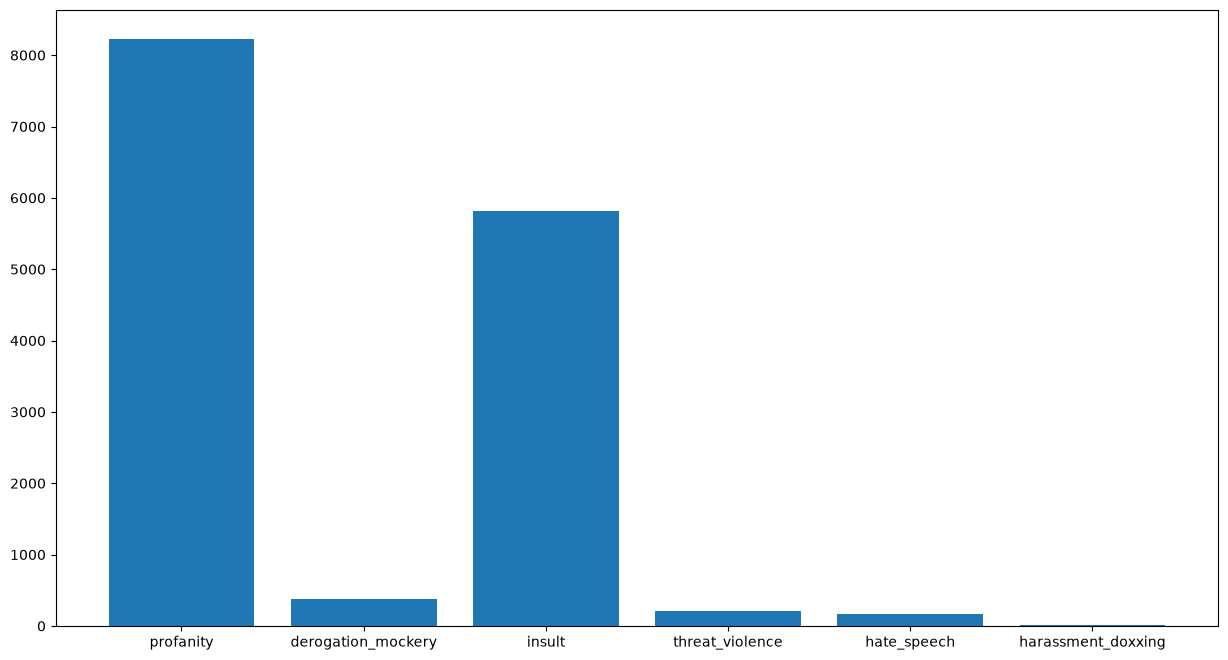

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

counts = Counter(categories)

plt.figure(figsize=(15,8))
plt.bar(counts.keys(), counts.values())
plt.show()




In [22]:
data = []
categories = []

with open("data\\ru_paradetox_toxic_spans.jsonl") as f:
    for line in f:
        item = json.loads(line)
        if item['entities'] and 'harassment_doxxing' not in [entity['category'] for entity in item['entities']]:
            data.append(item)
            for entity in item['entities']:
                categories.append(entity['category'])

In [23]:
for key, value in Counter(categories).items():
    print(f"{key}: {value}")

profanity: 8220
derogation_mockery: 381
insult: 5803
threat_violence: 215
hate_speech: 164
